In [4]:
from get_data.get_data import get_merged_events

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

merged_events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

In [5]:
from grid_areas.grid_areas import get_event_area

def add_areas_and_pos_merged_events(eventDataFrame, areas_x = 12, areas_y = 8):
    start_team = [team for team in eventDataFrame['possession_team'].values][0]
    
    event_start_locations = [[value[0], value[1]] if value != '' else '' for value in eventDataFrame['location'].values]
    event_end_locations = [[value['end_location'][0], value['end_location'][1]] if value != '' and 'end_location' in value.keys() else '' for value in eventDataFrame['event'].values]

    event_end_locations = [[abs(120.0 - float(location[0])), abs(80.0 - float(location[1]))] if team != start_team and location != '' else location for location, team in zip(event_end_locations, eventDataFrame['possession_team'].values)]

    event_start_areas = [get_event_area(location, areas_x, areas_y) if location != '' else '' for location in event_start_locations]
    event_end_areas = [get_event_area(location, areas_x, areas_y) if location != '' else '' for location in event_end_locations]

    event_area_codes = [f'{a}{b}' for a,b in zip(event_start_areas, event_end_areas)]
    newEventDataFrame = eventDataFrame

    newEventDataFrame['start_x'] = [value[0] if value != '' else '' for value in event_start_locations]
    newEventDataFrame['start_y'] = [value[1] if value != '' else '' for value in event_start_locations]

    newEventDataFrame['end_x'] = [value[0] if value != '' else '' for value in event_end_locations]
    newEventDataFrame['end_y'] = [value[1] if value != '' else '' for value in event_end_locations]

    newEventDataFrame['start_area'] = event_start_areas
    newEventDataFrame['end_area'] = event_end_areas
    newEventDataFrame['area_code'] = event_area_codes

    return newEventDataFrame

In [6]:
passes = merged_events[merged_events['possession_team'] == 'Poland']
passes = passes[merged_events['type'] == 'Pass']
passes = add_areas_and_pos_merged_events(passes)


areas = passes['start_area'].unique().tolist()
start_pass_areas = [area for area in passes['start_area'].values]
start_pass_areas_count = [(area, str(round((start_pass_areas.count(area) / len(start_pass_areas)) * 100, 2)) + '%') for area in start_pass_areas]
start_pass_areas_count = list(set(start_pass_areas_count))
start_pass_areas_count.sort(key=lambda y: y[0])

start_pass_areas_count

C:\Users\mattyl\AppData\Local\Temp\ipykernel_12228\372232372.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  passes = passes[merged_events['type'] == 'Pass']


[('A1', '0.88%'),
 ('A2', '0.18%'),
 ('A3', '0.35%'),
 ('A4', '0.71%'),
 ('A5', '0.71%'),
 ('A6', '0.53%'),
 ('A7', '0.18%'),
 ('A8', '0.18%'),
 ('B1', '0.18%'),
 ('B3', '0.53%'),
 ('B4', '1.06%'),
 ('B5', '0.53%'),
 ('B6', '0.18%'),
 ('B8', '0.18%'),
 ('C1', '0.71%'),
 ('C2', '0.71%'),
 ('C3', '1.24%'),
 ('C4', '1.94%'),
 ('C5', '0.71%'),
 ('C6', '0.35%'),
 ('C7', '0.53%'),
 ('C8', '0.35%'),
 ('D1', '1.77%'),
 ('D2', '0.53%'),
 ('D3', '1.24%'),
 ('D4', '0.35%'),
 ('D5', '1.94%'),
 ('D6', '0.71%'),
 ('D7', '0.88%'),
 ('D8', '1.24%'),
 ('E1', '1.06%'),
 ('E2', '2.47%'),
 ('E3', '1.06%'),
 ('E4', '1.41%'),
 ('E5', '1.77%'),
 ('E6', '2.65%'),
 ('E7', '4.06%'),
 ('E8', '1.24%'),
 ('F1', '1.41%'),
 ('F2', '1.24%'),
 ('F3', '1.77%'),
 ('F4', '2.83%'),
 ('F5', '1.06%'),
 ('F6', '1.94%'),
 ('F7', '2.12%'),
 ('F8', '2.12%'),
 ('G1', '1.06%'),
 ('G2', '1.06%'),
 ('G3', '0.53%'),
 ('G4', '1.77%'),
 ('G5', '1.06%'),
 ('G6', '1.24%'),
 ('G7', '1.41%'),
 ('G8', '3.0%'),
 ('H1', '1.24%'),
 ('H2', '0.

In [7]:
zero_area_count = []
i = 1
for area_count in start_pass_areas_count:
    if int(area_count[0][1]) != i:
        zero_area_count.append(area_count[0][0] + str(i))
        i = int(area_count[0][1])
    i += 1
    if i > 8:
        i = 1
        
zero_area_count

['B2', 'B7', 'K5', 'L4']

In [8]:
for item in zero_area_count:
    start_pass_areas_count.append((item, '0%'))

start_pass_areas_count.sort(key=lambda y: y[0])

start_pass_areas_count

[('A1', '0.88%'),
 ('A2', '0.18%'),
 ('A3', '0.35%'),
 ('A4', '0.71%'),
 ('A5', '0.71%'),
 ('A6', '0.53%'),
 ('A7', '0.18%'),
 ('A8', '0.18%'),
 ('B1', '0.18%'),
 ('B2', '0%'),
 ('B3', '0.53%'),
 ('B4', '1.06%'),
 ('B5', '0.53%'),
 ('B6', '0.18%'),
 ('B7', '0%'),
 ('B8', '0.18%'),
 ('C1', '0.71%'),
 ('C2', '0.71%'),
 ('C3', '1.24%'),
 ('C4', '1.94%'),
 ('C5', '0.71%'),
 ('C6', '0.35%'),
 ('C7', '0.53%'),
 ('C8', '0.35%'),
 ('D1', '1.77%'),
 ('D2', '0.53%'),
 ('D3', '1.24%'),
 ('D4', '0.35%'),
 ('D5', '1.94%'),
 ('D6', '0.71%'),
 ('D7', '0.88%'),
 ('D8', '1.24%'),
 ('E1', '1.06%'),
 ('E2', '2.47%'),
 ('E3', '1.06%'),
 ('E4', '1.41%'),
 ('E5', '1.77%'),
 ('E6', '2.65%'),
 ('E7', '4.06%'),
 ('E8', '1.24%'),
 ('F1', '1.41%'),
 ('F2', '1.24%'),
 ('F3', '1.77%'),
 ('F4', '2.83%'),
 ('F5', '1.06%'),
 ('F6', '1.94%'),
 ('F7', '2.12%'),
 ('F8', '2.12%'),
 ('G1', '1.06%'),
 ('G2', '1.06%'),
 ('G3', '0.53%'),
 ('G4', '1.77%'),
 ('G5', '1.06%'),
 ('G6', '1.24%'),
 ('G7', '1.41%'),
 ('G8', '3.0%'),

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Arc

def draw_pitch(ax, areas_x, areas_y, scale=1):
    # size of the pitch is 120, 80
    
    X = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P','Q','R','S','T']
    Y = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]

    #Pitch Outline & Centre Line
    plt.plot([0,0],[0,80*scale], color="black")
    plt.plot([0,120*scale],[80*scale,80*scale], color="black")
    plt.plot([120*scale,120*scale],[80*scale,0], color="black")
    plt.plot([120*scale,0],[0,0], color="black")
    plt.plot([60*scale,60*scale],[0,80*scale], color="black")
    
    for i in range (0,areas_x):
        plt.text((((60/areas_x)+i*120/areas_x)-1)*scale, 82*scale, X[i], fontdict=None, fontsize = 8*scale)
        
    for i in range (0,areas_y):
        plt.text(-3*scale, (((40/areas_y)+i*80/areas_y)-1)*scale, Y[i], fontdict=None, fontsize = 8*scale)

    #Left Penalty Area
    plt.plot([14.6*scale,14.6*scale],[57.8*scale,22.2*scale],color="black")
    plt.plot([0,14.6*scale],[57.8*scale,57.8*scale],color="black")
    plt.plot([0,14.6*scale],[22.2*scale,22.2*scale],color="black")

    #Right Penalty Area
    plt.plot([120*scale,105.4*scale],[57.8*scale,57.8*scale],color="black")
    plt.plot([105.4*scale,105.4*scale],[57.8*scale,22.5*scale],color="black")
    plt.plot([120*scale, 105.4*scale],[22.5*scale,22.5*scale],color="black")

    #Left 6-yard Box
    plt.plot([0,4.9*scale],[48*scale,48*scale],color="black")
    plt.plot([4.9*scale,4.9*scale],[48*scale,32*scale],color="black")
    plt.plot([0,4.9*scale],[32*scale,32*scale],color="black")

    #Right 6-yard Box
    plt.plot([120*scale,115.1*scale],[48*scale,48*scale],color="black")
    plt.plot([115.1*scale,115.1*scale],[48*scale,32*scale],color="black")
    plt.plot([120*scale,115.1*scale],[32*scale,32*scale],color="black")
    
    #Sectors
    for i in range(1, areas_y):
        plt.plot([120*scale,0],[(80/areas_y)*i*scale,(80/areas_y)*i*scale], color="gray")

    for i in range(1, areas_x):
        plt.plot([(120/areas_x)*i*scale,(120/areas_x)*i*scale],[80*scale,0], color="gray")
    
    #Prepare Circles
    centreCircle = plt.Circle((60*scale,40*scale),8.1*scale,color="black",fill=False)
    centreSpot = plt.Circle((60*scale,40*scale),0.71,color="black")
    leftPenSpot = plt.Circle((9.7*scale,40*scale),0.71,color="black")
    rightPenSpot = plt.Circle((110.3*scale,40*scale),0.71,color="black")

    #Draw Circles
    ax.add_patch(centreCircle)
    ax.add_patch(centreSpot)
    ax.add_patch(leftPenSpot)
    ax.add_patch(rightPenSpot)

def draw_areas_percents(areas_percents, scale):
    fig, ax = plt.subplots()
    fig.set_size_inches(7*scale, 5*scale)
    i = 0
    j = 0
    for area_percent in areas_percents:
        plt.text(12+(40*j), (40*i) + 20, area_percent[1], color='red', fontsize=16)
        i += 1
        if i > 7:
            j += 1
            i = 0
      
    draw_pitch(ax, 12, 8, scale)
    plt.show()

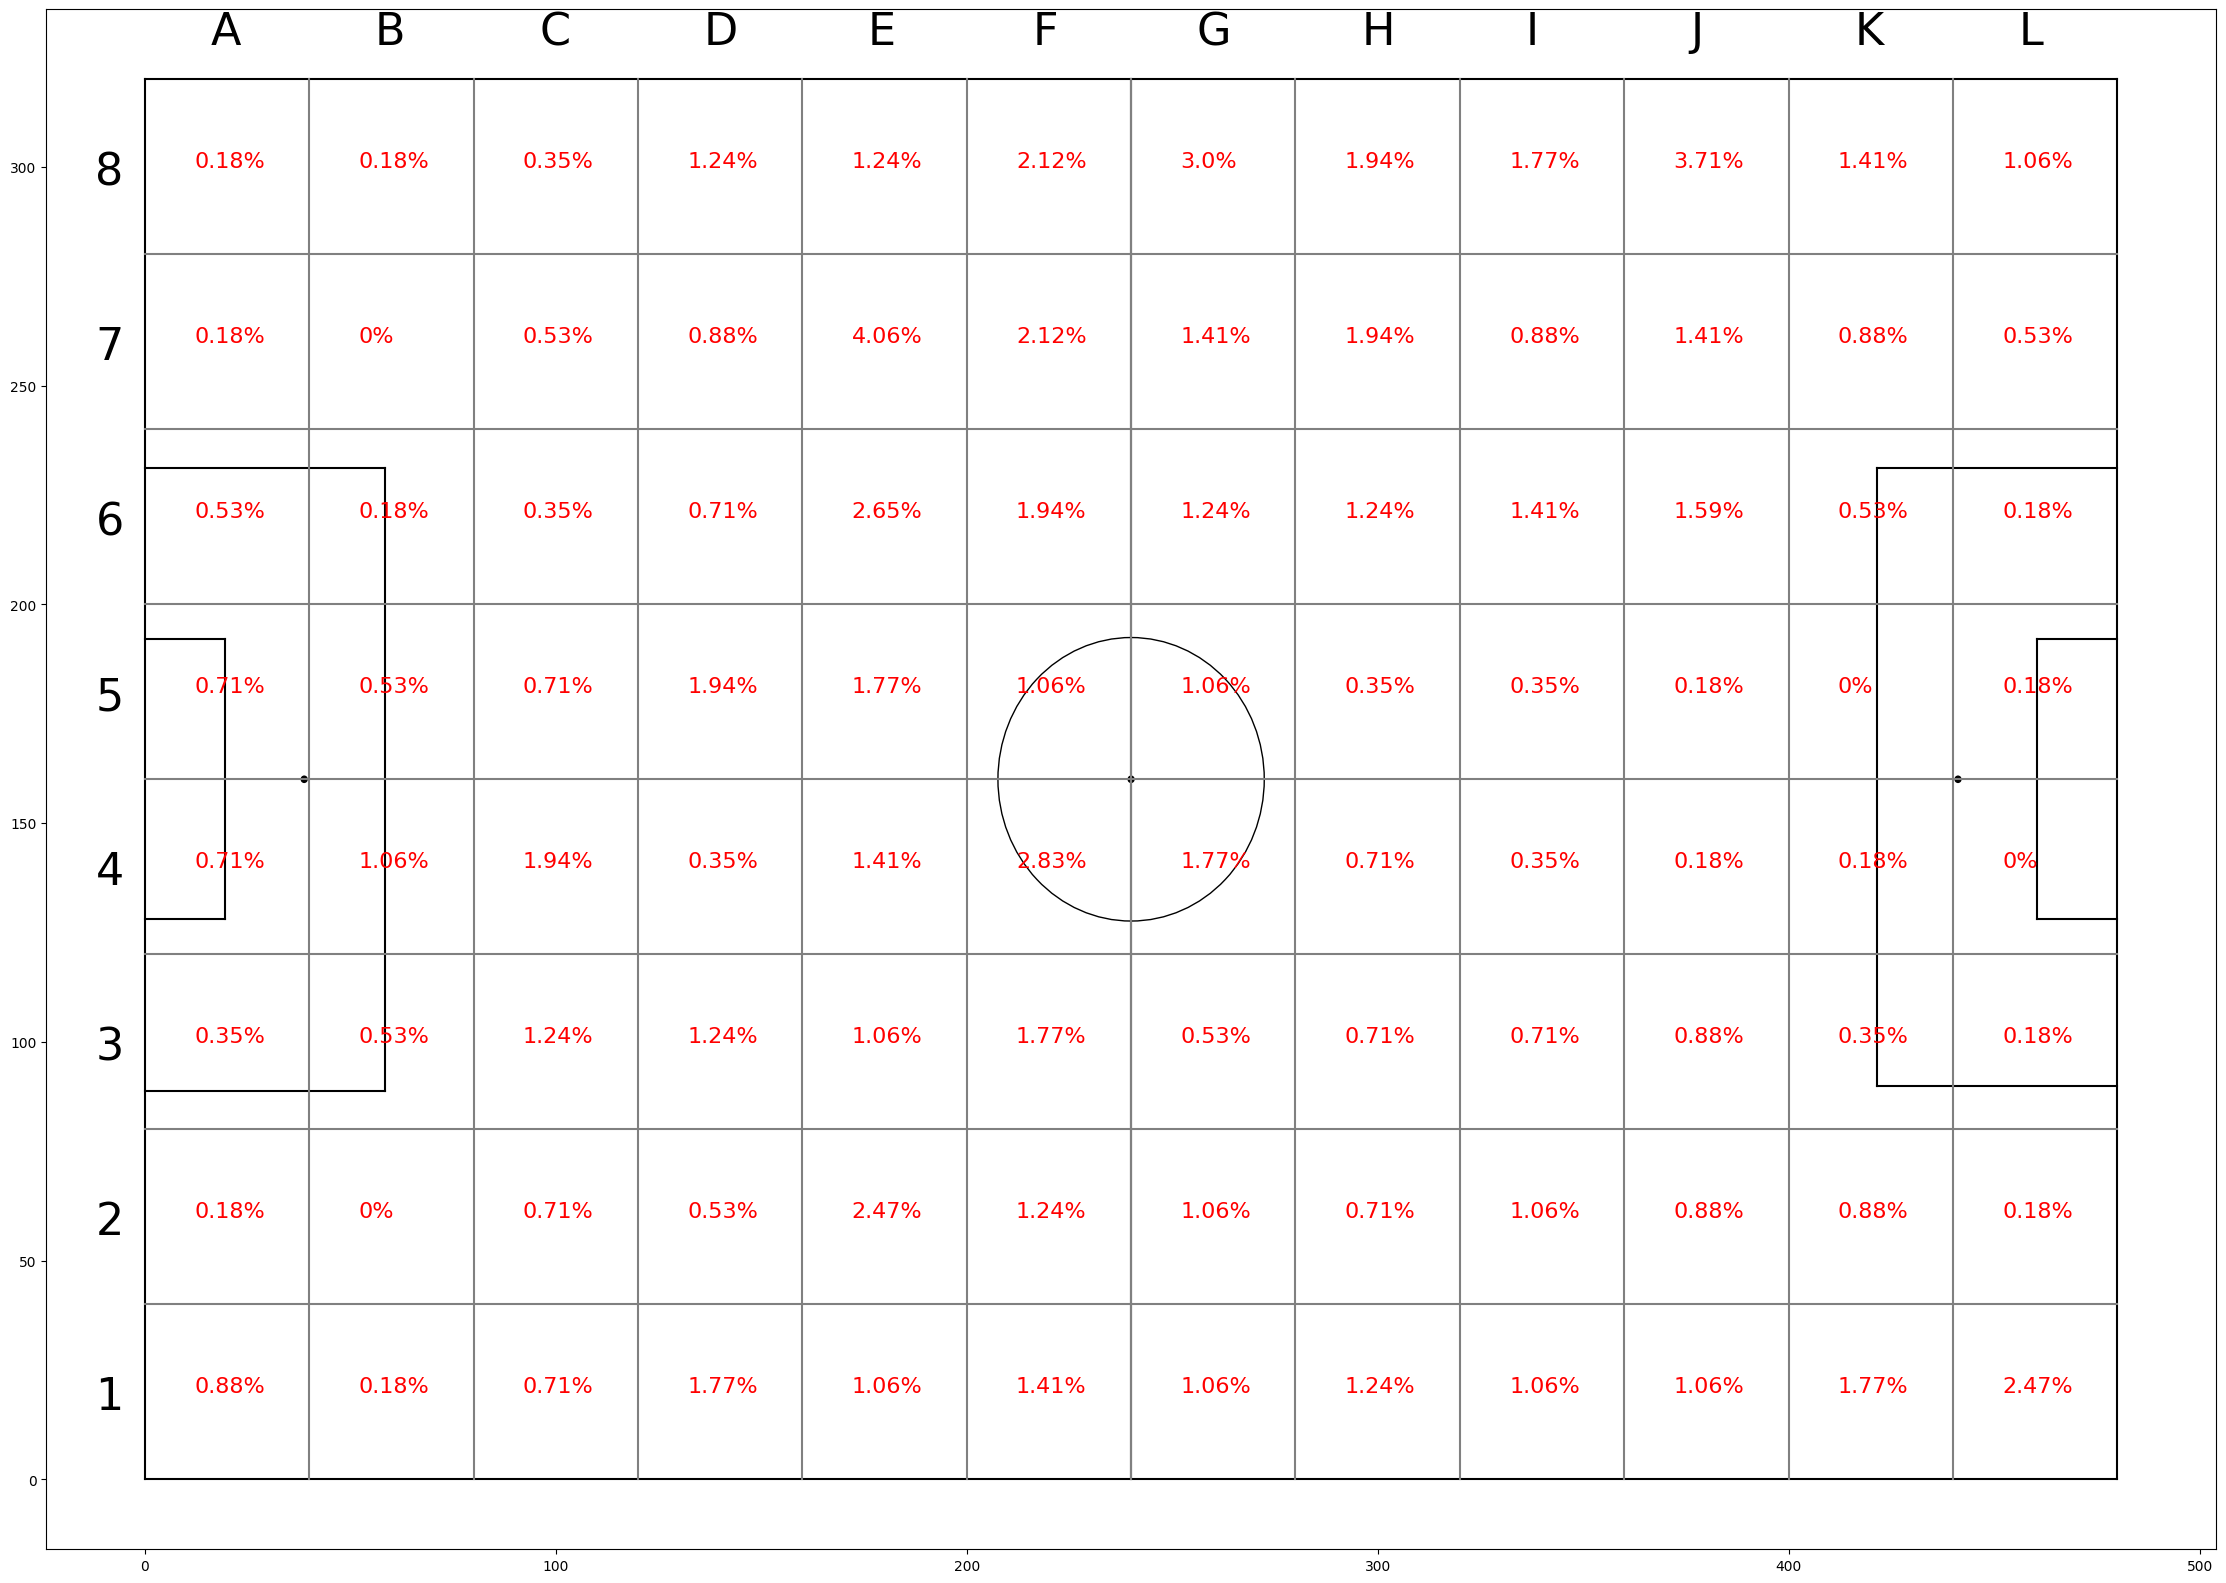

In [10]:
draw_areas_percents(start_pass_areas_count, 4)

In [24]:
passes = merged_events[merged_events['possession_team'] == 'Sweden']
passes = passes[merged_events['type'] == 'Pass']
passes = add_areas_and_pos_merged_events(passes)


areas = passes['start_area'].unique().tolist()
start_pass_areas = [area for area in passes['start_area'].values]
start_pass_areas_count = [(area, str(round((start_pass_areas.count(area) / len(start_pass_areas)) * 100, 2)) + '%') for area in start_pass_areas]
start_pass_areas_count = list(set(start_pass_areas_count))
start_pass_areas_count.sort(key=lambda y: y[0])

start_pass_areas_count

C:\Users\mattyl\AppData\Local\Temp\ipykernel_12228\1214411401.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  passes = passes[merged_events['type'] == 'Pass']


[('A2', '0.74%'),
 ('A3', '0.37%'),
 ('A4', '1.86%'),
 ('A5', '4.09%'),
 ('B1', '0.74%'),
 ('B2', '1.12%'),
 ('B3', '0.74%'),
 ('B4', '1.49%'),
 ('B5', '2.97%'),
 ('B6', '0.37%'),
 ('B8', '0.37%'),
 ('C1', '0.74%'),
 ('C3', '0.74%'),
 ('C4', '0.37%'),
 ('C5', '0.37%'),
 ('C6', '1.12%'),
 ('C7', '1.12%'),
 ('C8', '0.74%'),
 ('D1', '0.37%'),
 ('D2', '1.12%'),
 ('D3', '2.23%'),
 ('D4', '1.49%'),
 ('D5', '0.74%'),
 ('D6', '0.74%'),
 ('D7', '0.74%'),
 ('D8', '1.49%'),
 ('E1', '3.35%'),
 ('E2', '1.49%'),
 ('E3', '0.74%'),
 ('E4', '0.37%'),
 ('E6', '0.74%'),
 ('E7', '1.86%'),
 ('E8', '4.09%'),
 ('F1', '1.49%'),
 ('F2', '1.12%'),
 ('F3', '0.74%'),
 ('F4', '0.74%'),
 ('F5', '0.74%'),
 ('F6', '1.49%'),
 ('F7', '1.12%'),
 ('F8', '2.23%'),
 ('G1', '2.23%'),
 ('G2', '0.37%'),
 ('G3', '0.37%'),
 ('G4', '0.37%'),
 ('G5', '1.86%'),
 ('G6', '1.86%'),
 ('G7', '0.74%'),
 ('G8', '1.49%'),
 ('H1', '1.49%'),
 ('H2', '1.86%'),
 ('H4', '0.37%'),
 ('H5', '0.74%'),
 ('H6', '0.74%'),
 ('H7', '2.97%'),
 ('H8', '2

In [25]:
zero_area_count = []
i = 1
for area_count in start_pass_areas_count:
    print(int(area_count[0][1]))
    print(i)
    if int(area_count[0][1]) != i:
        zero_area_count.append(area_count[0][0] + str(i))
        i += 1
    i += 1
    if i > 8:
        i = 1
        
zero_area_count

2
1
3
3
4
4
5
5
1
6
2
8
3
1
4
3
5
5
6
6
8
7
1
1
3
2
4
4
5
5
6
6
7
7
8
8
1
1
2
2
3
3
4
4
5
5
6
6
7
7
8
8
1
1
2
2
3
3
4
4
6
5
7
7
8
8
1
1
2
2
3
3
4
4
5
5
6
6
7
7
8
8
1
1
2
2
3
3
4
4
5
5
6
6
7
7
8
8
1
1
2
2
4
3
5
5
6
6
7
7
8
8
1
1
2
2
3
3
4
4
5
5
7
6
8
8
1
1
2
2
3
3
4
4
5
5
6
6
7
7
8
8
1
1
2
2
3
3
4
4
6
5
7
7
8
8
1
1
3
2
6
4
8
6


['A1',
 'B6',
 'B8',
 'B1',
 'B3',
 'B7',
 'C2',
 'E5',
 'H3',
 'I6',
 'K5',
 'L2',
 'L4',
 'L6']

In [26]:
for item in zero_area_count:
    start_pass_areas_count.append((item, '0%'))

start_pass_areas_count.sort(key=lambda y: y[0])

start_pass_areas_count

[('A1', '0%'),
 ('A2', '0.74%'),
 ('A3', '0.37%'),
 ('A4', '1.86%'),
 ('A5', '4.09%'),
 ('B1', '0.74%'),
 ('B1', '0%'),
 ('B2', '1.12%'),
 ('B3', '0.74%'),
 ('B3', '0%'),
 ('B4', '1.49%'),
 ('B5', '2.97%'),
 ('B6', '0.37%'),
 ('B6', '0%'),
 ('B7', '0%'),
 ('B8', '0.37%'),
 ('B8', '0%'),
 ('C1', '0.74%'),
 ('C2', '0%'),
 ('C3', '0.74%'),
 ('C4', '0.37%'),
 ('C5', '0.37%'),
 ('C6', '1.12%'),
 ('C7', '1.12%'),
 ('C8', '0.74%'),
 ('D1', '0.37%'),
 ('D2', '1.12%'),
 ('D3', '2.23%'),
 ('D4', '1.49%'),
 ('D5', '0.74%'),
 ('D6', '0.74%'),
 ('D7', '0.74%'),
 ('D8', '1.49%'),
 ('E1', '3.35%'),
 ('E2', '1.49%'),
 ('E3', '0.74%'),
 ('E4', '0.37%'),
 ('E5', '0%'),
 ('E6', '0.74%'),
 ('E7', '1.86%'),
 ('E8', '4.09%'),
 ('F1', '1.49%'),
 ('F2', '1.12%'),
 ('F3', '0.74%'),
 ('F4', '0.74%'),
 ('F5', '0.74%'),
 ('F6', '1.49%'),
 ('F7', '1.12%'),
 ('F8', '2.23%'),
 ('G1', '2.23%'),
 ('G2', '0.37%'),
 ('G3', '0.37%'),
 ('G4', '0.37%'),
 ('G5', '1.86%'),
 ('G6', '1.86%'),
 ('G7', '0.74%'),
 ('G8', '1.49%')

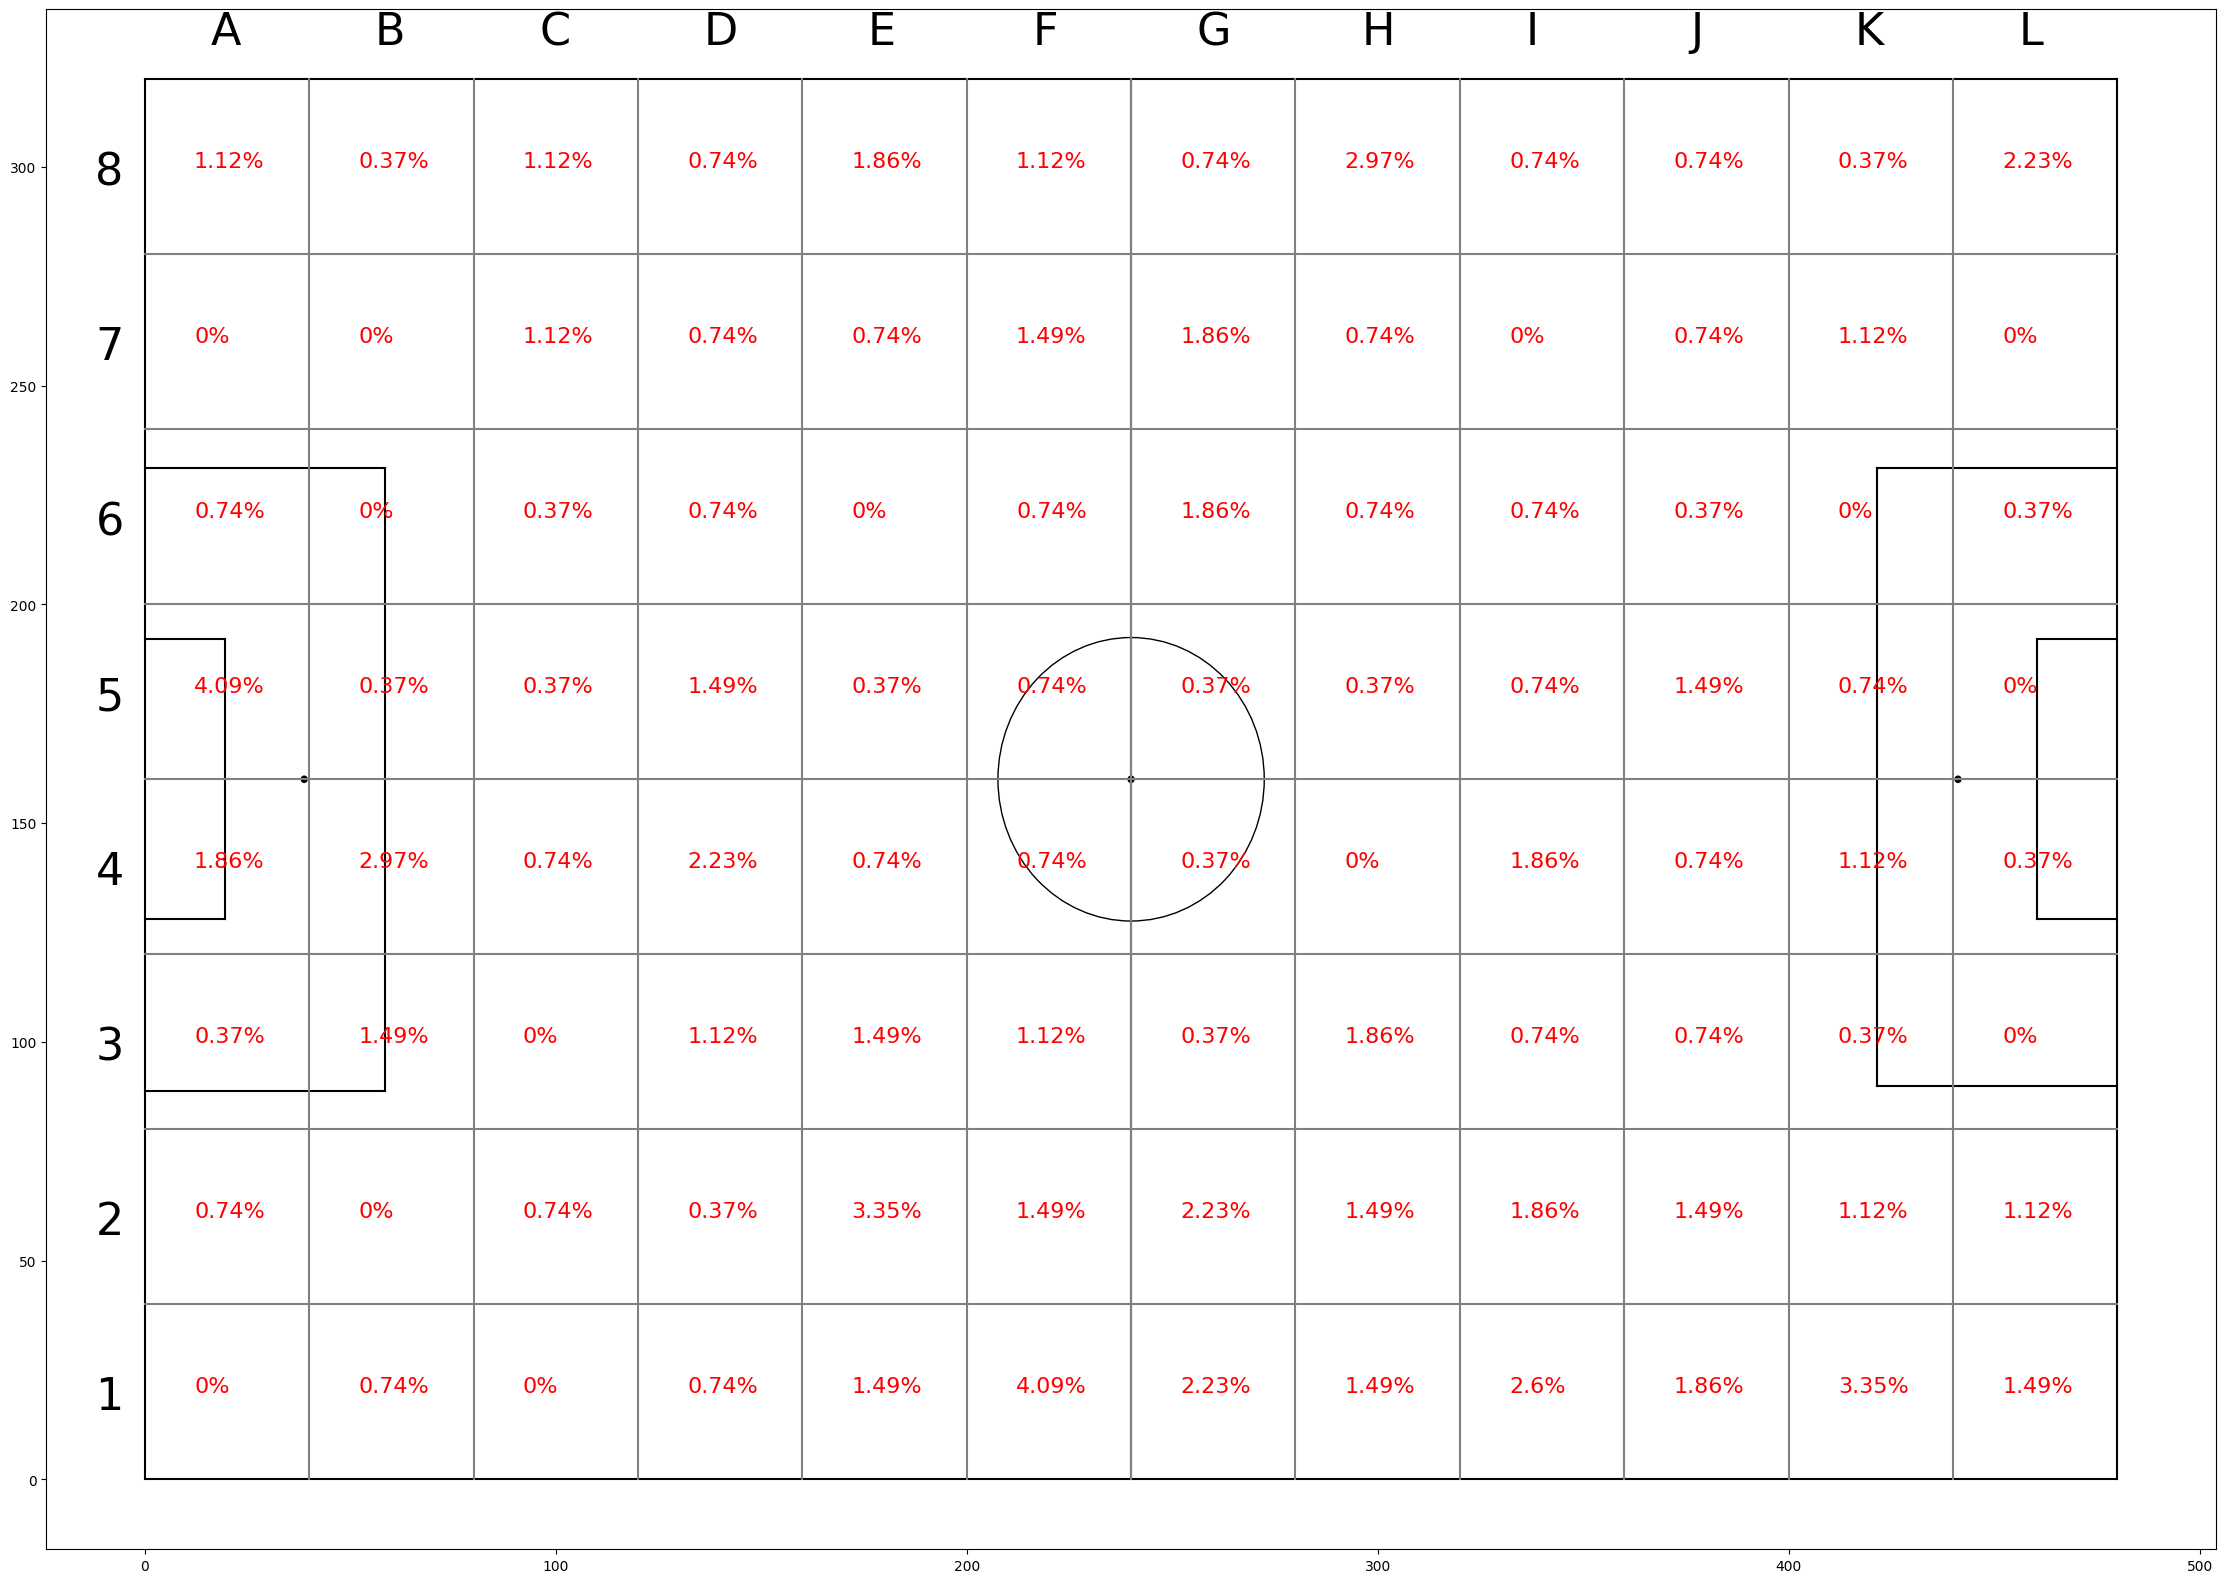

In [27]:
draw_areas_percents(start_pass_areas_count, 4)